<a href="https://colab.research.google.com/github/nour2344/RoadAnomaly-DeepLearning/blob/main/notebooks/06_unet_resnet34.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RoadAnomaly — U-Net avec ResNet34 pré-entraîné

## 1. Chargement des données et configuration

Nous utilisons une architecture U-Net avec un encodeur ResNet34 pré-entraîné sur ImageNet.

Cette approche repose sur le **Transfer Learning** : nous réutilisons des caractéristiques visuelles déjà apprises pour améliorer la segmentation des anomalies routières.

Nous conservons les mêmes ensembles Train, Validation et Test que pour les modèles précédents afin de comparer les performances.

In [2]:
from google.colab import drive
from pathlib import Path
import pandas as pd
import torch

drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/deep learning P")
SPLIT_PATH = PROJECT_DIR / "split_manifest.csv"

df = pd.read_csv(SPLIT_PATH)

train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df = df[df["split"] == "validation"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Train :", len(train_df))
print("Validation :", len(val_df))
print("Test :", len(test_df))
print("Device :", device)

Mounted at /content/drive
Train : 42
Validation : 9
Test : 9
Device : cuda


## 2. Préparation des données

Nous réutilisons le même prétraitement que pour CNN Baseline, U-Net et FCN :

- Redimensionnement à 256 × 256 avec padding.
- Conversion des masques : 0 (normal), 1 (anomalie).
- Augmentation uniquement pour les images d'entraînement.
- Normalisation des images avec les statistiques ImageNet pour ResNet34.
- Batch size : 4.

Les masques ne sont pas normalisés.

In [3]:
import numpy as np
from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader

IMG_SIZE = (256, 256)

IMAGENET_MEAN = np.array(
    [0.485, 0.456, 0.406], dtype=np.float32
)

IMAGENET_STD = np.array(
    [0.229, 0.224, 0.225], dtype=np.float32
)


def preprocess_image(path):
    image = Image.open(path).convert("RGB")

    image = ImageOps.pad(
        image,
        IMG_SIZE,
        method=Image.Resampling.BILINEAR,
        color=(0, 0, 0)
    )

    return np.asarray(image, dtype=np.float32) / 255.0


def preprocess_mask(path):
    mask = Image.open(path).convert("L")

    mask = ImageOps.pad(
        mask,
        IMG_SIZE,
        method=Image.Resampling.NEAREST,
        color=0
    )

    return (np.asarray(mask) == 2).astype(np.float32)


def augment_image_mask(image, mask, rng):
    if rng.random() < 0.5:
        image = np.flip(image, axis=1).copy()
        mask = np.flip(mask, axis=1).copy()

    image = np.clip(
        image * rng.uniform(0.8, 1.2), 0, 1
    )

    mean = image.mean(axis=(0, 1), keepdims=True)

    image = np.clip(
        (image - mean) * rng.uniform(0.8, 1.2) + mean,
        0, 1
    )

    return image.astype(np.float32), mask


class RoadAnomalyDataset(Dataset):

    def __init__(self, dataframe, augment=False):
        self.data = dataframe.reset_index(drop=True)
        self.augment = augment
        self.rng = np.random.default_rng(42)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]

        image = preprocess_image(row["image"])
        mask = preprocess_mask(row["mask"])

        if self.augment:
            image, mask = augment_image_mask(
                image, mask, self.rng
            )

        # Normalisation ImageNet
        image = (image - IMAGENET_MEAN) / IMAGENET_STD

        image = torch.from_numpy(
            np.ascontiguousarray(image.transpose(2, 0, 1))
        ).float()

        mask = torch.from_numpy(
            np.ascontiguousarray(mask[None, :, :])
        ).float()

        return image, mask


train_loader = DataLoader(
    RoadAnomalyDataset(train_df, augment=True),
    batch_size=4,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    RoadAnomalyDataset(val_df),
    batch_size=4,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    RoadAnomalyDataset(test_df),
    batch_size=4,
    shuffle=False,
    num_workers=0
)

images, masks = next(iter(train_loader))

print("Images :", images.shape)
print("Masques :", masks.shape)
print("Device :", device)

Images : torch.Size([4, 3, 256, 256])
Masques : torch.Size([4, 1, 256, 256])
Device : cuda


## 3. Construction de U-Net avec ResNet34

Nous utilisons le Transfer Learning avec un encodeur ResNet34 pré-entraîné sur ImageNet.

- **Encodeur ResNet34 :** extrait des caractéristiques visuelles déjà apprises.
- **Décodeur U-Net :** reconstruit le masque de segmentation.
- **Skip connections :** combinent les caractéristiques de différentes résolutions.
- **Sortie :** un canal correspondant aux logits des pixels anormaux.

Nous entraînons l'ensemble du réseau afin de l'adapter aux anomalies routières.

In [4]:
!pip -q install segmentation-models-pytorch

In [5]:
import torch
import segmentation_models_pytorch as smp

# U-Net avec encodeur ResNet34 pré-entraîné
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
    activation=None
).to(device)

# Vérifier les dimensions
images, masks = next(iter(train_loader))

model.eval()

with torch.no_grad():
    outputs = model(images.to(device))

print("Entrée :", images.shape)
print("Sortie :", outputs.shape)
print("Masques réels :", masks.shape)

print(
    "Nombre de paramètres :",
    sum(p.numel() for p in model.parameters())
)

print(
    "Paramètres entraînables :",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

print("Encodeur :", model.encoder.__class__.__name__)
print("Device :", device)

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Entrée : torch.Size([4, 3, 256, 256])
Sortie : torch.Size([4, 1, 256, 256])
Masques réels : torch.Size([4, 1, 256, 256])
Nombre de paramètres : 24436369
Paramètres entraînables : 24436369
Encodeur : ResNetEncoder
Device : cuda


## 4. Fonction de perte et optimiseur

Nous utilisons une combinaison de BCE Loss et Dice Loss pour entraîner le modèle.

- **BCE Loss :** mesure les erreurs de classification des pixels.
- **Dice Loss :** tient compte du déséquilibre entre pixels normaux et anormaux.
- **Adam :** optimise tous les paramètres du réseau.
- **Learning rate :** 0.0001, adapté au fine-tuning d'un modèle pré-entraîné.

La perte finale est composée de 50 % BCE et 50 % Dice.

In [6]:
import torch
import torch.nn as nn

# BCE Loss
bce_loss = nn.BCEWithLogitsLoss()

# Dice Loss
def dice_loss(logits, targets, smooth=1.0):
    probs = torch.sigmoid(logits)

    intersection = (probs * targets).sum(dim=(1, 2, 3))
    union = (
        probs.sum(dim=(1, 2, 3))
        + targets.sum(dim=(1, 2, 3))
    )

    dice = (2 * intersection + smooth) / (union + smooth)

    return 1 - dice.mean()


# Combined Loss
def combined_loss(logits, targets):
    bce = bce_loss(logits, targets)
    dice = dice_loss(logits, targets)

    return 0.5 * bce + 0.5 * dice


# Optimiseur pour le fine-tuning
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0001
)

# Vérification sur un batch
images, masks = next(iter(train_loader))

images = images.to(device)
masks = masks.to(device)

model.eval()

with torch.no_grad():
    outputs = model(images)

    bce = bce_loss(outputs, masks)
    dice = dice_loss(outputs, masks)
    loss = combined_loss(outputs, masks)

print("BCE Loss :", round(bce.item(), 4))
print("Dice Loss :", round(dice.item(), 4))
print("Combined Loss :", round(loss.item(), 4))
print("Optimizer : Adam")
print("Learning rate :", optimizer.param_groups[0]["lr"])

BCE Loss : 0.5771
Dice Loss : 0.9625
Combined Loss : 0.7698
Optimizer : Adam
Learning rate : 0.0001


## 5. Entraînement et validation de U-Net ResNet34

Nous effectuons le fine-tuning de U-Net avec un encodeur ResNet34 pré-entraîné sur ImageNet.

- **Epochs :** maximum 30.
- **Batch size :** 4.
- **Learning rate :** 0.0001.
- **Early Stopping :** arrêt après 6 époques sans amélioration.
- **Checkpoint :** sauvegarde du meilleur modèle selon la Validation Loss.

Nous utilisons la même fonction BCE + Dice Loss que pour les modèles précédents.

In [7]:
import torch
from pathlib import Path

EPOCHS = 30
PATIENCE = 6

best_val_loss = float("inf")
patience_counter = 0

train_losses = []
val_losses = []

# Dossier de sauvegarde
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "unet_resnet34_best.pth"

for epoch in range(EPOCHS):

    # Entraînement
    model.train()
    train_loss = 0.0

    for images, masks in train_loader:
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = combined_loss(outputs, masks)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

    train_loss /= len(train_loader.dataset)

    # Validation
    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for images, masks in val_loader:
            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)
            loss = combined_loss(outputs, masks)

            val_loss += loss.item() * images.size(0)

    val_loss /= len(val_loader.dataset)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

    # Sauvegarde du meilleur modèle
    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        patience_counter = 0

        torch.save(model.state_dict(), MODEL_PATH)

    else:
        patience_counter += 1

    # Early Stopping
    if patience_counter >= PATIENCE:
        print("\nEarly Stopping activated.")
        break

print("\nTraining completed!")
print("Best Validation Loss :", round(best_val_loss, 4))
print("Model saved at :", MODEL_PATH)

Epoch 01/30 | Train Loss: 0.8553 | Val Loss: 1.2173
Epoch 02/30 | Train Loss: 0.7587 | Val Loss: 0.9591
Epoch 03/30 | Train Loss: 0.7088 | Val Loss: 0.8030
Epoch 04/30 | Train Loss: 0.6671 | Val Loss: 0.7622
Epoch 05/30 | Train Loss: 0.6283 | Val Loss: 0.6567
Epoch 06/30 | Train Loss: 0.6017 | Val Loss: 0.6226
Epoch 07/30 | Train Loss: 0.5768 | Val Loss: 0.6008
Epoch 08/30 | Train Loss: 0.5530 | Val Loss: 0.5748
Epoch 09/30 | Train Loss: 0.5361 | Val Loss: 0.5518
Epoch 10/30 | Train Loss: 0.5241 | Val Loss: 0.5398
Epoch 11/30 | Train Loss: 0.5092 | Val Loss: 0.5302
Epoch 12/30 | Train Loss: 0.4940 | Val Loss: 0.5182
Epoch 13/30 | Train Loss: 0.4873 | Val Loss: 0.5000
Epoch 14/30 | Train Loss: 0.4813 | Val Loss: 0.4929
Epoch 15/30 | Train Loss: 0.4652 | Val Loss: 0.4838
Epoch 16/30 | Train Loss: 0.4591 | Val Loss: 0.4798
Epoch 17/30 | Train Loss: 0.4552 | Val Loss: 0.4693
Epoch 18/30 | Train Loss: 0.4433 | Val Loss: 0.4619
Epoch 19/30 | Train Loss: 0.4364 | Val Loss: 0.4658
Epoch 20/30 

## 6. Analyse des courbes d'apprentissage

Nous visualisons les pertes d'entraînement et de validation de U-Net ResNet34.

Cette analyse permet d'observer la convergence du modèle pré-entraîné et de détecter un éventuel surapprentissage.

La meilleure Validation Loss est de 0.3901, obtenue à l'époque 30.

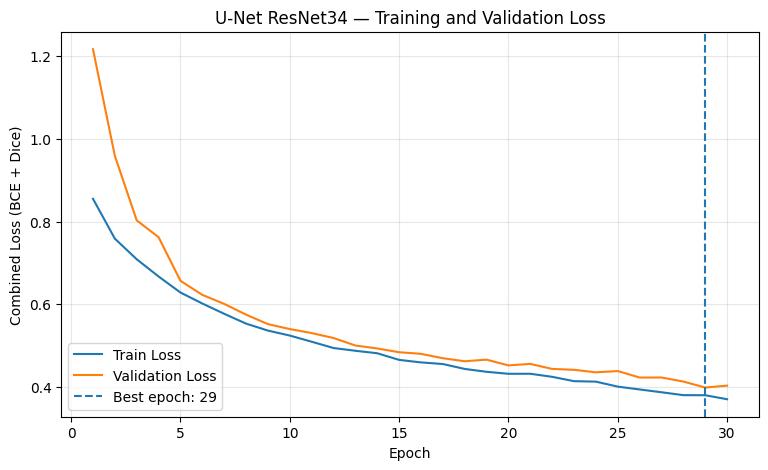

Best epoch : 29
Best Validation Loss : 0.3983


In [8]:
import matplotlib.pyplot as plt
import numpy as np

epochs = np.arange(1, len(train_losses) + 1)
best_epoch = int(np.argmin(val_losses)) + 1

plt.figure(figsize=(9, 5))

plt.plot(epochs, train_losses, label="Train Loss")
plt.plot(epochs, val_losses, label="Validation Loss")

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best epoch: {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Combined Loss (BCE + Dice)")
plt.title("U-Net ResNet34 — Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Best epoch :", best_epoch)
print("Best Validation Loss :", round(min(val_losses), 4))

## Évaluation de U-Net ResNet34

Nous évaluons le meilleur modèle sur les 9 images de test avec les métriques IoU, Dice, Precision et Recall.

Le seuil de classification est fixé à 0.5 pour conserver les mêmes conditions que les modèles précédents.

In [9]:
# Recharger le meilleur modèle sauvegardé
model.load_state_dict(
    torch.load(MODEL_PATH, map_location=device, weights_only=True)
)
model.eval()

TP = FP = FN = 0

with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)
        predictions = torch.sigmoid(outputs) >= 0.5
        targets = masks >= 0.5

        TP += (predictions & targets).sum().item()
        FP += (predictions & ~targets).sum().item()
        FN += (~predictions & targets).sum().item()

eps = 1e-7

iou = TP / (TP + FP + FN + eps)
dice = 2 * TP / (2 * TP + FP + FN + eps)
precision = TP / (TP + FP + eps)
recall = TP / (TP + FN + eps)

print("U-Net ResNet34 — Test Results")
print(f"IoU       : {iou:.4f}")
print(f"Dice      : {dice:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")

U-Net ResNet34 — Test Results
IoU       : 0.7351
Dice      : 0.8474
Precision : 0.8152
Recall    : 0.8822


## Visualisation des prédictions U-Net ResNet34

Nous comparons les images originales, les masques réels et les prédictions pour vérifier si les anomalies routières sont correctement localisées.

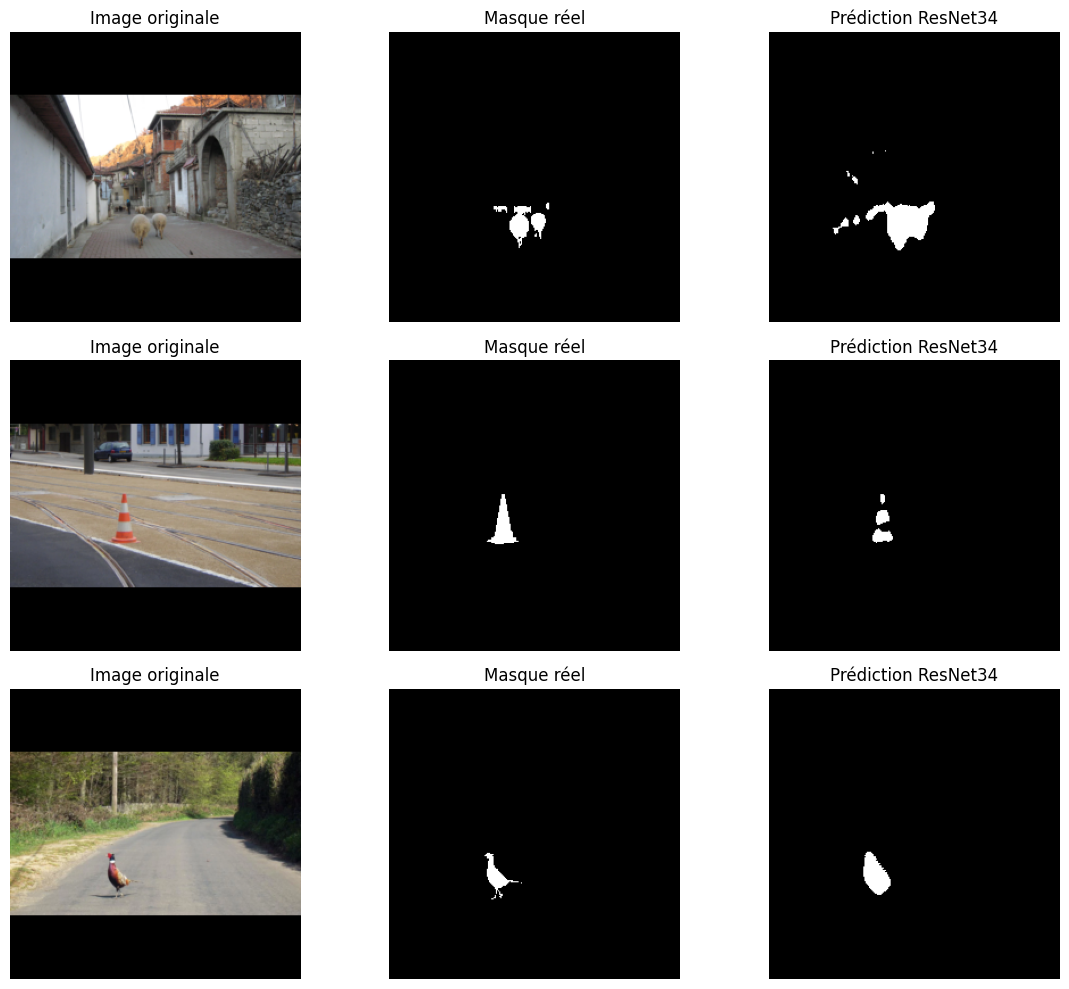

In [11]:
import torch
import matplotlib.pyplot as plt

model.eval()
test_dataset = test_loader.dataset

# Normalisation ImageNet utilisée par ResNet34
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

fig, axes = plt.subplots(3, 3, figsize=(12, 10))

with torch.no_grad():
    for i in range(3):
        image, mask = test_dataset[i]

        logits = model(image.unsqueeze(0).to(device))
        pred = (torch.sigmoid(logits) >= 0.5)

        # Dénormaliser uniquement pour l'affichage
        image_display = image.cpu() * std + mean
        image_display = image_display.clamp(0, 1)

        image_np = image_display.permute(1, 2, 0).numpy()
        mask_np = mask.squeeze().cpu().numpy()
        pred_np = pred.squeeze().cpu().numpy()

        axes[i, 0].imshow(image_np)
        axes[i, 0].set_title("Image originale")

        axes[i, 1].imshow(mask_np, cmap="gray", vmin=0, vmax=1)
        axes[i, 1].set_title("Masque réel")

        axes[i, 2].imshow(pred_np, cmap="gray", vmin=0, vmax=1)
        axes[i, 2].set_title("Prédiction ResNet34")

        for ax in axes[i]:
            ax.axis("off")

plt.tight_layout()
plt.show()

## Conclusion — U-Net ResNet34

Nous avons entraîné un modèle U-Net avec un encodeur ResNet34 pour la segmentation sémantique des anomalies routières.

Le meilleur modèle a été obtenu à l'époque 30 avec une Validation Loss de 0.3901.

### Résultats sur le Test

| Métrique | CNN Baseline | U-Net | U-Net ResNet34 |
|---|---|---|---|
| IoU | 0.1925 | 0.2707 | **0.7351** |
| Dice | 0.3229 | 0.4260 | **0.8474** |
| Precision | 0.4104 | 0.3582 | **0.8152** |
| Recall | 0.2661 | 0.5257 | **0.8822** |

### Analyse

U-Net ResNet34 obtient les meilleures performances parmi les modèles comparés.

Les prédictions montrent une bonne localisation des obstacles, malgré certaines erreurs de délimitation et quelques faux positifs.

Ces résultats suggèrent que l'utilisation d'un encodeur ResNet34 améliore fortement la segmentation sur notre jeu de données.

Cependant, le test comporte seulement 9 images, ce qui limite la généralisation des conclusions.

### Conclusion

U-Net ResNet34 est actuellement notre meilleur modèle de segmentation sémantique pour RoadAnomaly.